# Hodgkin–Huxley Dynamics with a Voltage-Gated Calcium Current

**Computational Neuroscience Independent Study | Project 2**

This project asks how an illustrative calcium current changes action potentials and intracellular calcium in a single-compartment Hodgkin–Huxley model. It combines numerical simulation, measurements of spike responses, and equilibrium stability analysis.

**Reading guide:** Sections 1–2 define the model; Section 3 shows the baseline response; Sections 4–5 compare calcium conductances and measure the responses; Section 6 examines equilibrium and local stability.

**Scope:** This is an educational computational model. The calcium parameters are illustrative and have not been fitted to a particular neuronal subtype. See the [project README](README.md) for results, execution instructions, and verification limits.

**Preservation note:** The original code cells, explanatory text, and saved outputs are retained below. This introductory cell and the file name are presentation additions. The uploaded notebook is preserved separately in `original/`.


# Project 2: Hodgkin–Huxley Model with a Voltage-Gated Calcium Current

## 1. Objective and Model Overview

### Scientific question

How does adding a simplified voltage-gated calcium current change neuronal voltage responses and intracellular calcium dynamics?

We will compare the classical Hodgkin–Huxley model without a calcium current against models with different maximum calcium conductances. The comparisons will examine spike shape, response latency, afterdepolarization, and intracellular calcium transients.

### Starting point

The classical Hodgkin–Huxley model describes membrane voltage using sodium, potassium, and leak currents:

$$
C_m \frac{dV}{dt}
=
I_{\mathrm{ext}}
-
I_{\mathrm{Na}}
-
I_{\mathrm{K}}
-
I_{\mathrm{L}}.
$$

Its state variables are membrane voltage, $V$, and three dimensionless gating variables: $m$, $h$, and $n$.

### Extension introduced in this project

We add a voltage-gated calcium current to the membrane equation:

$$
C_m \frac{dV}{dt}
=
I_{\mathrm{ext}}
-
I_{\mathrm{Na}}
-
I_{\mathrm{K}}
-
I_{\mathrm{L}}
-
I_{\mathrm{Ca}}.
$$

The calcium current is:

$$
I_{\mathrm{Ca}}
=
g_{\mathrm{Ca}} d^2 f
\left(V-E_{\mathrm{Ca}}\right),
$$

where $g_{\mathrm{Ca}}$ is the maximum calcium conductance, $d$ is the activation gate, and $f$ is the inactivation gate.

We also track intracellular calcium concentration, $[\mathrm{Ca}]_i$. The complete state vector is:

$$
\mathbf{y}(t)
=
\begin{pmatrix}
V(t) \\
m(t) \\
h(t) \\
n(t) \\
d(t) \\
f(t) \\
[\mathrm{Ca}]_i(t)
\end{pmatrix}.
$$

### Variables and units

| Variable | Interpretation | Units |
|---|---|---|
| $t$ | Time | $\mathrm{ms}$ |
| $V$ | Membrane voltage | $\mathrm{mV}$ |
| $m$ | Sodium activation gate | Dimensionless |
| $h$ | Sodium availability through its inactivation gate | Dimensionless |
| $n$ | Potassium activation gate | Dimensionless |
| $d$ | Calcium activation gate | Dimensionless |
| $f$ | Calcium availability through its inactivation gate | Dimensionless |
| $[\mathrm{Ca}]_i$ | Intracellular calcium concentration | $\mathrm{\mu M}$ |

Current densities are expressed in $\mathrm{\mu A/cm^2}$, conductances per unit area in $\mathrm{mS/cm^2}$, and membrane capacitance per unit area in $\mathrm{\mu F/cm^2}$.

### Current sign convention

Ionic currents are defined as positive when directed outward. They are therefore subtracted in the membrane equation.

An inward calcium current has $I_{\mathrm{Ca}}<0$. Its contribution, $-I_{\mathrm{Ca}}$, is positive and promotes depolarization.

### Assumptions and limits

- We treat the neuron as one unit, with the same voltage everywhere.
- The calcium gates are a simplified way to model how calcium channels open and close. They are not based on measurements of one specific type of calcium channel.
- The calcium reversal potential, $E_{\mathrm{Ca}}$, remains fixed.
- Intracellular calcium formula follows a simplified balance between the contribution of calcium current and a return toward a baseline concentration.
- Intracellular calcium concentration does not feed back into the voltage or gating equations in this version.
- Sodium and potassium concentrations are not tracked explicitly.
- The added calcium parameters are illustrative rather than experimentally validated estimates for a particular neuronal subtype.

### Comparison strategy

We will compare:

$$
g_{\mathrm{Ca}}
\in
\{0,\;0.4,\;1,\;2\}
\;\mathrm{mS/cm^2}.
$$

The case $g_{\mathrm{Ca}}=0$ is the control without calcium current. The assignment's calcium-conductance baseline is $0.4\;\mathrm{mS/cm^2}$.

Across these comparisons, we will keep the stimulus, remaining model parameters, initial-state protocol, and numerical settings unchanged.

We will distinguish predictions made before simulation from observed results and their interpretation. We will not assume that increasing calcium conductance necessarily increases sustained firing.


## 2. Adding Calcium to the Model

### 2.1. What changes?

We keep the sodium, potassium, and leak currents from Project 1.

We add three state variables:

- $d$: the calcium activation gate.
- $f$: the calcium inactivation gate.
- $[\mathrm{Ca}]_i$: the calcium concentration inside the cell.

The calcium current affects the voltage and changes the calcium concentration inside the cell.

### 2.2. Calcium current

The calcium current is:

$$
I_{\mathrm{Ca}}
=
g_{\mathrm{Ca}}d^2f(V-E_{\mathrm{Ca}}).
$$

Each part has a different role:

| Term | Meaning |
|---|---|
| $g_{\mathrm{Ca}}$ | Maximum calcium conductance |
| $d^2f$ | Fraction of that conductance available at the current time |
| $V-E_{\mathrm{Ca}}$ | Difference between the voltage and the calcium reversal potential |

The conductance available at a given time is:

$$
g_{\mathrm{Ca,eff}}=g_{\mathrm{Ca}}d^2f.
$$

Changing $g_{\mathrm{Ca}}$ changes the maximum conductance. Changes in $d$ and $f$ change how much of that conductance is available.

When $V<E_{\mathrm{Ca}}$, the calcium current is negative under our sign convention. This means calcium enters the cell.

Because the membrane equation subtracts $I_{\mathrm{Ca}}$, this inward current contributes to an increase in voltage.

### 2.3. How the calcium gates change

The activation gate follows:

$$
\frac{dd}{dt}
=
\frac{d_\infty(V)-d}{\tau_d}.
$$

The inactivation gate follows:

$$
\frac{df}{dt}
=
\frac{f_\infty(V)-f}{\tau_f}.
$$

The symbols $d_\infty(V)$ and $f_\infty(V)$ give the values that the gates approach if the voltage stays fixed.

They are targets that depend on voltage. They are not always equal to the current values of $d$ and $f$.

For example:

- If $d<d_\infty(V)$, then $dd/dt>0$, so $d$ increases.
- If $d>d_\infty(V)$, then $dd/dt<0$, so $d$ decreases.
- If $d=d_\infty(V)$, then $dd/dt=0$.

The same reasoning applies to $f$.

The time constants, $\tau_d$ and $\tau_f$, control how quickly the gates move toward their targets. A smaller time constant gives a faster response to the same difference between the target and the current gate value.

### 2.4. Voltage-dependent gate targets

The assignment defines:

$$
d_\infty(V)
=
\frac{1}{1+\exp\left(-(V+20)/7\right)},
$$

$$
f_\infty(V)
=
\frac{1}{1+\exp\left((V+25)/8\right)}.
$$

As voltage increases:

- The target for activation, $d_\infty$, increases.
- The target for availability, $f_\infty$, decreases.

This means depolarization can increase calcium activation while also reducing calcium availability over time.

The gates do not reach their new targets immediately. Their time constants determine how quickly they respond.

For this model:

$$
\tau_d=3\;\mathrm{ms},
\qquad
\tau_f=40\;\mathrm{ms}.
$$

The activation gate responds faster than the inactivation gate.

### 2.5. We are going to track calcium concentration

Calcium current describes the movement of electric charge across the membrane.

Calcium concentration describes how much calcium is present inside the cell per unit of volume.

These are different quantities. To track the concentration, we need another equation:

$$
\frac{d[\mathrm{Ca}]_i}{dt}
=
-\eta I_{\mathrm{Ca}}
-
\frac{[\mathrm{Ca}]_i-\mathrm{Ca}_{\mathrm{rest}}}
{\tau_{\mathrm{Ca}}}.
$$

The first term connects the calcium current to a change in concentration:

$$
-\eta I_{\mathrm{Ca}}.
$$

An inward calcium current is negative, so this term is positive and increases the concentration.

The parameter $\eta$ converts current density into a rate of change in concentration. Here, it is a simplified conversion rather than a detailed description of the cell's shape and calcium handling.

The second term moves the concentration back toward its baseline:

$$
-\frac{[\mathrm{Ca}]_i-\mathrm{Ca}_{\mathrm{rest}}}
{\tau_{\mathrm{Ca}}}.
$$

If the concentration is above baseline, this term is negative. If it equals baseline, this term is zero.

This term summarizes the return toward baseline. It does not describe each calcium removal process separately.

### 2.6. Expected sequence during a response

Before running the simulation, I expect the following sequence:

1. A rise in voltage changes the targets ($d_\infty(V)$) of the calcium gates.
2. The activation gate moves toward its new target.
3. If the gates allow calcium current and $V<E_{\mathrm{Ca}}$, calcium enters the cell.
4. This current contributes to depolarization and increases intracellular calcium.
5. Changes in the gates and voltage change the calcium current over time.
6. When calcium current becomes small, the concentration moves back toward baseline. This happens because the return term is negative when calcium is above baseline and becomes stronger than the remaining input from the calcium current (see calcium concnetration formula in 2.5)

These are predictions from the equations. We still need to compare them with the simulation.

### 2.7. A limitation of this model

We calculate intracellular calcium, but we do not use that concentration to update $E_{\mathrm{Ca}}$ or the gates.

Therefore, calcium current changes both voltage and concentration, but the concentration does not feed back into the voltage dynamics which in the actual neuron, we know it does.

In [2]:
# ==================== 1. IMPORTS ====================
import numpy as np  # Provide arrays and exponential functions.


# ==================== 2. MODEL PARAMETERS ====================
params = {  # Keep all model parameters in one place.
    "C_m": 1.0,  # Membrane capacitance in uF/cm^2.
    "g_Na": 120.0,  # Maximum sodium conductance in mS/cm^2.
    "g_K": 36.0,  # Maximum potassium conductance in mS/cm^2.
    "g_L": 0.3,  # Leak conductance in mS/cm^2.
    "E_Na": 50.0,  # Sodium reversal potential in mV.
    "E_K": -77.0,  # Potassium reversal potential in mV.
    "E_L": -54.4,  # Leak reversal potential in mV.
    "g_Ca": 0.4,  # Baseline maximum calcium conductance in mS/cm^2.
    "E_Ca": 120.0,  # Fixed calcium reversal potential in mV.
    "tau_d": 3.0,  # Calcium activation time constant in ms.
    "tau_f": 40.0,  # Calcium inactivation time constant in ms.
    "eta": 0.0002,  # Current-to-concentration factor in uM*cm^2/(uA*ms).
    "Ca_rest": 0.05,  # Baseline calcium concentration in uM.
    "tau_Ca": 80.0,  # Calcium return time constant in ms.
}  # End the parameter registry.


# ==================== 3. STABLE RATE CALCULATION ====================
def vtrap(x):  # Calculate x / (1 - exp(-x)) for one number.
    if x == 0.0:  # Check for the point where direct division would fail.
        return 1.0  # Use the mathematical limit at zero.
    return x / (-np.expm1(-x))  # Calculate the ratio accurately near zero.


# ==================== 4. SODIUM AND POTASSIUM GATING RATES ====================
def alpha_m(V):  # Calculate the rate that increases m, in 1/ms.
    return 1.0 * vtrap((V + 40.0) / 10.0)  # Keep the HH rate finite at -40 mV.


def beta_m(V):  # Calculate the rate that decreases m, in 1/ms.
    return 4.0 * np.exp(-(V + 65.0) / 18.0)  # Calculate the backward activation rate.


def alpha_h(V):  # Calculate the rate that increases h, in 1/ms.
    return 0.07 * np.exp(-(V + 65.0) / 20.0)  # Calculate recovery from sodium inactivation.


def beta_h(V):  # Calculate the rate that decreases h, in 1/ms.
    return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))  # Calculate the sodium inactivation rate.


def alpha_n(V):  # Calculate the rate that increases n, in 1/ms.
    return 0.1 * vtrap((V + 55.0) / 10.0)  # Keep the HH rate finite at -55 mV.


def beta_n(V):  # Calculate the rate that decreases n, in 1/ms.
    return 0.125 * np.exp(-(V + 65.0) / 80.0)  # Calculate the backward potassium activation rate.


# ==================== 5. CALCIUM GATE STEADY-STATE VALUES ====================
def d_inf(V):  # Find the value d approaches if voltage stays fixed.
    return 1.0 / (1.0 + np.exp(-(V + 20.0) / 7.0))  # Increase calcium activation with voltage.


def f_inf(V):  # Find the value f approaches if voltage stays fixed.
    return 1.0 / (1.0 + np.exp((V + 25.0) / 8.0))  # Decrease calcium availability with voltage.


# ==================== 6. INJECTED CURRENT ====================
def I_ext(t, amplitude=10.0, onset=20.0, offset=120.0):  # Set the pulse amplitude in uA/cm^2 and its times in ms.
    return amplitude if onset <= t < offset else 0.0  # Apply current only during the pulse.


# ==================== 7. INITIAL STATE ====================
def initial_state(V0=-65.0, parameters=params):  # Set the initial voltage and the other six state values.
    m0 = alpha_m(V0) / (alpha_m(V0) + beta_m(V0))  # Start m at its steady-state value for V0.
    h0 = alpha_h(V0) / (alpha_h(V0) + beta_h(V0))  # Start h at its steady-state value for V0.
    n0 = alpha_n(V0) / (alpha_n(V0) + beta_n(V0))  # Start n at its steady-state value for V0.
    d0 = d_inf(V0)  # Start calcium activation at its steady-state value for V0.
    f0 = f_inf(V0)  # Start calcium availability at its steady-state value for V0.
    Ca0 = parameters["Ca_rest"]  # Start intracellular calcium at baseline in uM.
    return np.array([V0, m0, h0, n0, d0, f0, Ca0], dtype=float)  # Keep the state order V, m, h, n, d, f, Ca.


# ==================== 8. IONIC CURRENTS ====================
def ionic_currents(y, parameters=params):  # Calculate currents from one state or saved state columns.
    V, m, h, n, d, f, Ca = y  # Read the seven state variables in their declared order.
    I_Na = parameters["g_Na"] * m**3 * h * (V - parameters["E_Na"])  # Calculate sodium current in uA/cm^2.
    I_K = parameters["g_K"] * n**4 * (V - parameters["E_K"])  # Calculate potassium current in uA/cm^2.
    I_L = parameters["g_L"] * (V - parameters["E_L"])  # Calculate leak current in uA/cm^2.
    I_Ca = parameters["g_Ca"] * d**2 * f * (V - parameters["E_Ca"])  # Calculate calcium current using a fixed reversal potential.
    return I_Na, I_K, I_L, I_Ca  # Return outward-positive ionic currents.


# ==================== 9. SEVEN COUPLED DIFFERENTIAL EQUATIONS ====================
def hh_calcium(t, y, I, parameters=params):  # Receive time, state, a stimulus function, and model parameters.
    V, m, h, n, d, f, Ca = y  # Read the current voltage, five gates, and calcium concentration.
    I_Na, I_K, I_L, I_Ca = ionic_currents(y, parameters)  # Calculate all four currents from the same state.
    dV_dt = (I(t) - I_Na - I_K - I_L - I_Ca) / parameters["C_m"]  # Calculate voltage change in mV/ms.
    dm_dt = alpha_m(V) * (1.0 - m) - beta_m(V) * m  # Calculate the change in sodium activation in 1/ms.
    dh_dt = alpha_h(V) * (1.0 - h) - beta_h(V) * h  # Calculate the change in sodium availability in 1/ms.
    dn_dt = alpha_n(V) * (1.0 - n) - beta_n(V) * n  # Calculate the change in potassium activation in 1/ms.
    dd_dt = (d_inf(V) - d) / parameters["tau_d"]  # Move d toward its steady-state value at the current voltage.
    df_dt = (f_inf(V) - f) / parameters["tau_f"]  # Move f toward its steady-state value at the current voltage.
    dCa_dt = -parameters["eta"] * I_Ca - (Ca - parameters["Ca_rest"]) / parameters["tau_Ca"]  # Combine calcium input and return toward baseline, in uM/ms.
    return np.array([dV_dt, dm_dt, dh_dt, dn_dt, dd_dt, df_dt, dCa_dt])  # Return derivatives in the same order as the state.

> **Note:** We use the classical HH initial states, as required by the assignment. However, adding calcium current changes the balance of currents, so this initial state may not be an equilibrium of the new model. Voltage and intracellular calcium may therefore change before the external current starts (this does not necessarily mean that a spike will occur).

## 3. Baseline Simulation

### 3.1. Purpose

We will first run the model with the baseline calcium conductance:

$$
g_{\mathrm{Ca}}=0.4\;\mathrm{mS/cm^2}.
$$

This simulation will help us check how voltage, the five gates, and intracellular calcium change before, during, and after the current pulse.

### 3.2. Initial conditions

We will use the initial conditions required by the assignment:

$$
V(0)=-65\;\mathrm{mV}.
$$

The sodium and potassium gates start at their steady-state values for this voltage:

$$
m(t=0)=m_\infty(-65),\qquad
h(0)=h_\infty(-65),\qquad
n(0)=n_\infty(-65).
$$

The calcium gates also start at their steady-state values for the same voltage:

$$
d(0)=d_\infty(-65),\qquad
f(0)=f_\infty(-65).
$$

Intracellular calcium starts at baseline:

$$
[\mathrm{Ca}]_i(0)=0.05\;\mathrm{\mu M}.
$$

These conditions do not guarantee equilibrium of the full model. We will also inspect the response before the current pulse starts.

### 3.3. Current pulse

We will simulate from $0$ to $250\;\mathrm{ms}$.

The injected current will be:

$$
I_{\mathrm{ext}}(t)=
\begin{cases}
10\;\mathrm{\mu A/cm^2}, & 20\leq t<120\;\mathrm{ms},\\
0, & \text{otherwise}.
\end{cases}
$$

### 3.4. Numerical method

We will use `solve_ivp` with `LSODA` to solve the seven equations together in one call.

The solver will receive:

- The function `hh_calcium`, which calculates the seven derivatives.
- The initial state from `initial_state`.
- The current function `I_ext`.
- The model parameters.
- The simulation interval and requested output times.

We will use:

$$
\mathrm{rtol}=10^{-7},
\qquad
\mathrm{atol}=10^{-9}.
$$

We will request saved results every $0.01\;\mathrm{ms}$.

This output spacing does not set the solver's internal step size. LSODA chooses its internal steps while controlling its estimated numerical error.

### 3.5. Baseline figure

We will create five panels with the same time axis:

| Panel | Variables | What we will observe |
|---|---|---|
| 1 | $V$ | The voltage response |
| 2 | $m,h,n$ | Sodium and potassium gate changes |
| 3 | $d,f$ | Calcium gate changes |
| 4 | $[\mathrm{Ca}]_i$ | Calcium buildup and return toward baseline |
| 5 | $I_{\mathrm{ext}}$ | When the stimulus is applied |

We will label the units and save the figure as a PNG at 300 dpi.

### 3.6. Questions to examine

- Does voltage change before the pulse starts?
- How do the calcium gates change during the voltage response?
- Does intracellular calcium remain above baseline between spikes?
- After the pulse, does calcium decrease toward baseline?
- Do the curves show anything that needs further checking?

We will describe these observations after running the simulation. 

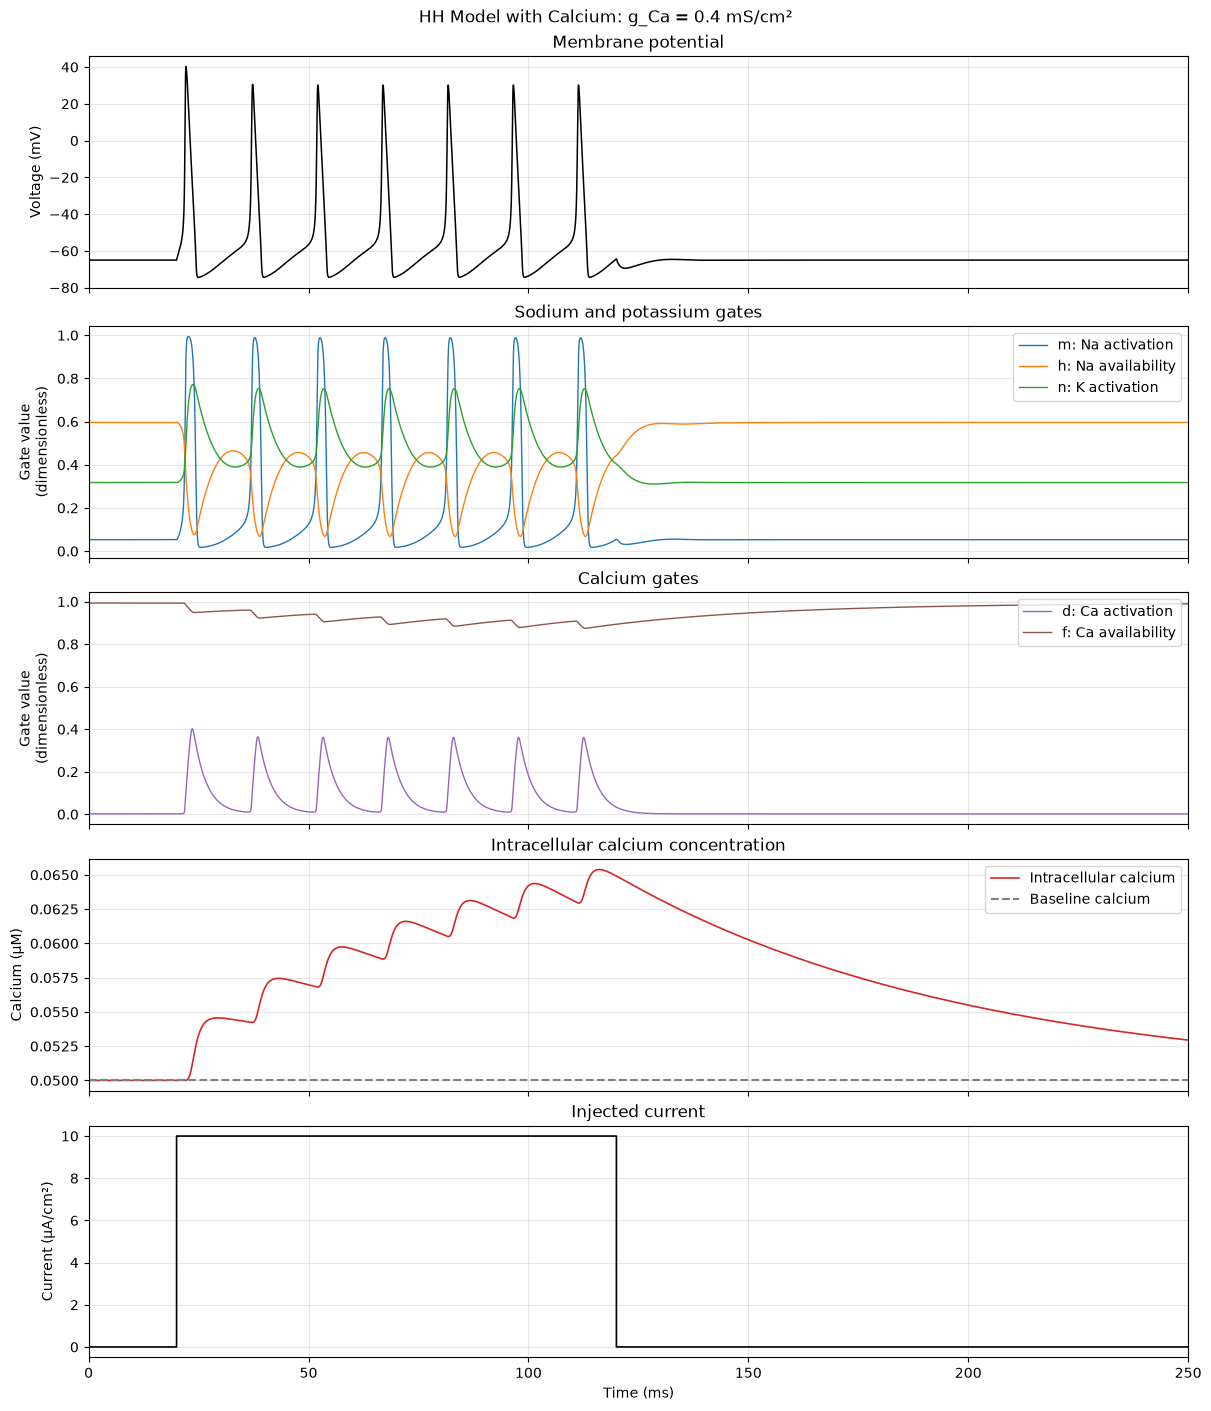

In [3]:
# ==================== 10. IMPORT SOLVER AND PLOTTING TOOLS ====================
from scipy.integrate import solve_ivp  # Import the function that solves the ODE system.
import matplotlib.pyplot as plt  # Import tools for plotting the results.


# ==================== 11. SET THE SIMULATION OPTIONS ====================
t_start = 0.0  # Start the simulation at 0 ms.
t_end = 250.0  # End the simulation at 250 ms.
dt_output = 0.01  # Request saved results every 0.01 ms.
n_intervals = round((t_end - t_start) / dt_output)  # Calculate the number of output intervals.
t_eval = np.linspace(t_start, t_end, n_intervals + 1)  # Include both ends of the time interval.
method = "LSODA"  # Use the same solver as in Project 1.
rtol = 1e-7  # Set the relative error tolerance.
atol = 1e-9  # Set the absolute error tolerance.
y0 = initial_state(parameters=params)  # Build the seven initial values using the assignment's initial-state rules.


# ==================== 12. RUN THE BASELINE SIMULATION ====================
solution = solve_ivp(  # Solve the seven equations together in one call.
    fun=hh_calcium,  # Use the function that calculates the seven derivatives.
    t_span=(t_start, t_end),  # Set the complete simulation interval.
    y0=y0,  # Pass the initial values in the order V, m, h, n, d, f, Ca.
    args=(I_ext, params),  # Pass the current function and the baseline model parameters.
    method=method,  # Use LSODA to choose internal steps during integration.
    t_eval=t_eval,  # Store the solution at the requested output times.
    rtol=rtol,  # Apply the relative error tolerance.
    atol=atol,  # Apply the absolute error tolerance.
)  # Finish the solver call.

if not solution.success:  # Check whether the solver reported a failure.
    raise RuntimeError(solution.message)  # Stop and show the reason for the failure.


# ==================== 13. EXTRACT THE RESULTS ====================
t = solution.t  # Read the saved times in ms.
V, m, h, n, d, f, Ca = solution.y  # Read the voltage, five gates, and calcium concentration.
I_trace = np.array([I_ext(time) for time in t])  # Calculate the injected current at each saved time.


# ==================== 14. CREATE THE BASELINE FIGURE ====================
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True, constrained_layout=True)  # Create five panels with a shared time axis.
fig.suptitle(f"HH Model with Calcium: g_Ca = {params['g_Ca']:g} mS/cm²")  # Identify the calcium conductance used in this run.


# ==================== 15. PLOT THE VOLTAGE ====================
axes[0].plot(t, V, color="black", linewidth=1.1)  # Plot the membrane voltage.
axes[0].set_title("Membrane potential")  # Name the voltage panel.
axes[0].set_ylabel("Voltage (mV)")  # Label the voltage units.


# ==================== 16. PLOT THE SODIUM AND POTASSIUM GATES ====================
axes[1].plot(t, m, label="m: Na activation", color="tab:blue", linewidth=1.0)  # Plot sodium activation.
axes[1].plot(t, h, label="h: Na availability", color="tab:orange", linewidth=1.0)  # Plot sodium availability.
axes[1].plot(t, n, label="n: K activation", color="tab:green", linewidth=1.0)  # Plot potassium activation.
axes[1].set_title("Sodium and potassium gates")  # Name the gate panel.
axes[1].set_ylabel("Gate value\n(dimensionless)")  # State that the gate values have no units.
axes[1].legend(loc="upper right")  # Identify the three gate curves.


# ==================== 17. PLOT THE CALCIUM GATES ====================
axes[2].plot(t, d, label="d: Ca activation", color="tab:purple", linewidth=1.0)  # Plot calcium activation.
axes[2].plot(t, f, label="f: Ca availability", color="tab:brown", linewidth=1.0)  # Plot calcium availability.
axes[2].set_title("Calcium gates")  # Name the calcium gate panel.
axes[2].set_ylabel("Gate value\n(dimensionless)")  # Label the dimensionless gate values.
axes[2].legend(loc="upper right")  # Identify the two calcium gate curves.


# ==================== 18. PLOT INTRACELLULAR CALCIUM ====================
axes[3].plot(t, Ca, color="tab:red", label="Intracellular calcium", linewidth=1.2)  # Plot calcium concentration inside the cell.
axes[3].axhline(params["Ca_rest"], color="gray", linestyle="--", label="Baseline calcium")  # Mark the baseline concentration for comparison.
axes[3].set_title("Intracellular calcium concentration")  # Name the concentration panel.
axes[3].set_ylabel("Calcium (µM)")  # Label the concentration units.
axes[3].legend(loc="upper right")  # Identify the concentration curve and baseline reference.


# ==================== 19. PLOT THE INJECTED CURRENT ====================
axes[4].step(t, I_trace, where="post", color="black", linewidth=1.2)  # Draw the injected current as a rectangular pulse.
axes[4].set_title("Injected current")  # Name the stimulus panel.
axes[4].set_ylabel("Current (µA/cm²)")  # Label the injected current density.
axes[4].set_xlabel("Time (ms)")  # Label the shared time axis.
axes[4].set_xlim(t_start, t_end)  # Show the complete simulation interval in all panels.


# ==================== 20. SAVE AND DISPLAY THE FIGURE ====================
for ax in axes:  # Apply the same grid style to each panel.
    ax.grid(True, alpha=0.3)  # Add a light grid to help read the curves.
fig.savefig("project_2_baseline.png", dpi=300, bbox_inches="tight")  # Save the figure in the current working folder at 300 dpi.
plt.show()  # Display the five panels in the notebook.

### Analysis: Calcium Buildup and Model Limits

This figure helps us see a limit of the model. Calcium concentration rises with each spike and falls slightly between spikes, but it builds up during the spike train. Meanwhile, the voltage does not show the same steady rise.

At first, I thought that keeping more positive calcium ions inside the cell should make the voltage rise over time, except positive charges leaves through other currents, such as potassium.

Our model includes these electrical currents, but it does not track sodium or potassium concentrations. Therefore, we cannot use these results to determine how their concentrations change or whether potassium is being depleted.

What's happening is that intracellular calcium does not feed back into the voltage equation. Calcium current affects voltage, but the calcium that builds up does not change the fixed calcium reversal potential or the gates, which in reality happens.

### Analysis II: Why Calcium Builds Up During the Current Pulse

The injected current affects calcium through this chain:

$$
I_{\mathrm{ext}}
\longrightarrow V
\longrightarrow d,f
\longrightarrow I_{\mathrm{Ca}}
\longrightarrow [\mathrm{Ca}]_i.
$$

The injected current promotes depolarization, which changes the calcium gates. When the gates allow inward calcium current, calcium enters the neuron.

In this simulation, each spike produces a rise in calcium concentration. Between spikes, the concentration falls slightly, but the next spike arrives before it returns to baseline. Calcium therefore builds up because its input is greater than its return toward baseline over these cycles.

When the pulse ends and calcium entry becomes small enough, the return term dominates because the concentration ifs very diferent from the rest concentration (which is a parameter), so the concentration decreases.

Note: The baseline parameter, $\mathrm{Ca}_{\mathrm{rest}}$, stays fixed. What rises is the actual calcium concentration, including its level between spikes. More injected current does not always mean more calcium: the result depends on voltage, gate activation, gate availability, and the balance between calcium input and return.

---

## 4. Comparing Different Calcium Conductances

### 4.1. Purpose

We will test how changing the maximum calcium conductance affects voltage, calcium current, and calcium buildup.

### 4.2. Conditions

We will compare four values:

$$
g_{\mathrm{Ca}}
\in
\{0,\;0.4,\;1,\;2\}
\;\mathrm{mS/cm^2}.
$$

| Maximum calcium conductance | Role |
|---|---|
| $0\;\mathrm{mS/cm^2}$ | Control without calcium current |
| $0.4\;\mathrm{mS/cm^2}$ | Baseline calcium model |
| $1\;\mathrm{mS/cm^2}$ | Higher calcium conductance |
| $2\;\mathrm{mS/cm^2}$ | Highest calcium conductance in this comparison |

We will change only $g_{\mathrm{Ca}}$. The injected current, pulse timing, other parameters, initial conditions, and numerical settings will remain the same.

Each simulation will start from the assignment's initial conditions, not from the final state of the previous run.

### 4.3. Prediction Before Simulation

For the same voltage and gate values, increasing $g_{\mathrm{Ca}}$ increases the size of calcium current:

$$
I_{\mathrm{Ca}}
=
g_{\mathrm{Ca}}d^2f(V-E_{\mathrm{Ca}}).
$$

I would predict that more current -> more depolarization -> neuron reaches spiking threshold easier -> higher firing frequency

However, voltage and gates do not stay unchanged during the simulation, which can end up changing behavior. So it's not that simple. 

### 4.4. What We Will Plot

We will compare the models using the same time axis and a consistent color for each conductance.

| Variable | Question |
|---|---|
| Membrane voltage, $V$ | Does the response start earlier? Do spike shape or firing patterns change? |
| Calcium current, $I_{\mathrm{Ca}}$ | How does calcium entry change? |
| Intracellular calcium, $[\mathrm{Ca}]_i$ | How much calcium builds up, and how does it decrease afterward? |
| Sodium availability, $h$ | Does sodium availability recover differently between spikes? |
| Injected current, $I_{\mathrm{ext}}$ | What stimulus is shared by all models? |

For each model, we will calculate calcium current using that model's own voltage and gates.

### 4.5. What We Will Measure Later

After inspecting the curves, we will define and calculate the measurements requested by the assignment:

- Peak voltage.
- Spike width at half-height.
- Depolarization after a spike.
- Peak intracellular calcium.
- First-spike latency.

We will define the measurement rules before comparing values, so the same rules are used for every model.

### 4.6. Interpretation Limits

Because the initial state is not guaranteed to be an equilibrium for every conductance, we will also inspect the period before the current pulse.


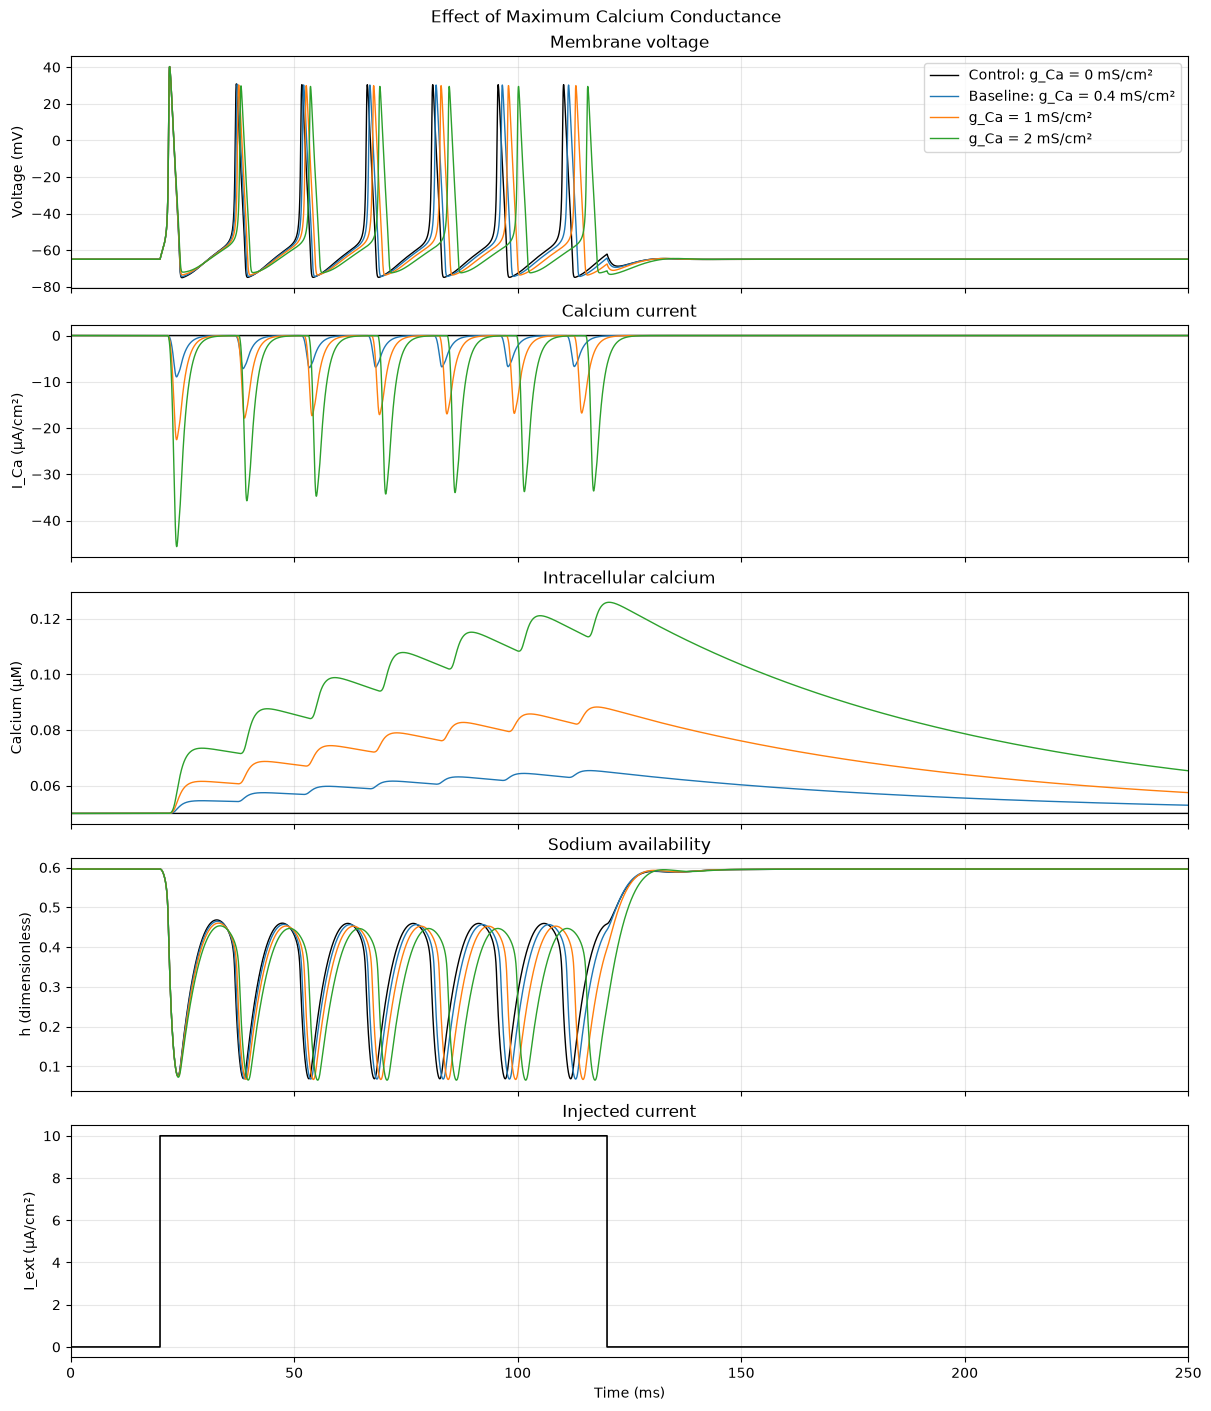

In [4]:
# ==================== 21. SET THE CALCIUM CONDUCTANCES ====================
g_Ca_values = (0.0, 0.4, 1.0, 2.0)  # Define the control, baseline, and higher conductances in mS/cm^2.
colors = ("black", "tab:blue", "tab:orange", "tab:green")  # Give each model one color across all panels.
calcium_results = {}  # Prepare a dictionary to save the results of each simulation.


# ==================== 22. CREATE THE COMPARISON FIGURE ====================
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True, constrained_layout=True)  # Create five panels with the same time axis.
fig.suptitle("Effect of Maximum Calcium Conductance")  # Add a title to the complete figure.


# ==================== 23. SIMULATE EACH CALCIUM CONDUCTANCE ====================
for g_Ca_value, color in zip(g_Ca_values, colors):  # Pair each conductance with its plotting color.
    model_params = params.copy()  # Copy the baseline parameters for this model.
    model_params["g_Ca"] = g_Ca_value  # Change only the maximum calcium conductance.
    label = f"g_Ca = {g_Ca_value:g} mS/cm²"  # Write the conductance value for the legend.

    if g_Ca_value == 0.0:  # Identify the model without calcium current.
        label = "Control: " + label  # Mark the calcium-free control in the legend.

    if g_Ca_value == 0.4:  # Identify the illustrative calcium baseline.
        label = "Baseline: " + label  # Mark the baseline in the legend.

    result = solve_ivp(  # Solve the seven equations for this conductance.
        fun=hh_calcium,  # Use the same HH model with calcium for every simulation.
        t_span=(t_start, t_end),  # Keep the simulation interval unchanged.
        y0=y0.copy(),  # Start each simulation from the same initial state.
        args=(I_ext, model_params),  # Pass the common current and this model's parameters.
        method=method,  # Use the same solver for every simulation.
        t_eval=t_eval,  # Save the results at the same times.
        rtol=rtol,  # Keep the relative tolerance unchanged.
        atol=atol,  # Keep the absolute tolerance unchanged.
    )  # Finish the solver call.

    if not result.success:  # Check whether this simulation completed successfully.
        raise RuntimeError(f"g_Ca = {g_Ca_value}: {result.message}")  # Stop and show which simulation failed.

    V_run, m_run, h_run, n_run, d_run, f_run, Ca_run = result.y  # Extract the seven state trajectories.
    I_Na_run, I_K_run, I_L_run, I_Ca_run = ionic_currents(result.y, model_params)  # Calculate currents using this model's own states.
    calcium_results[g_Ca_value] = {"parameters": model_params, "solution": result, "I_Ca": I_Ca_run}  # Save this model's results.

    axes[0].plot(result.t, V_run, color=color, label=label, linewidth=1.0)  # Compare membrane voltage.
    axes[1].plot(result.t, I_Ca_run, color=color, label=label, linewidth=1.0)  # Compare calcium current.
    axes[2].plot(result.t, Ca_run, color=color, label=label, linewidth=1.0)  # Compare intracellular calcium.
    axes[3].plot(result.t, h_run, color=color, label=label, linewidth=1.0)  # Compare sodium availability.


# ==================== 24. PLOT THE SHARED CURRENT PULSE ====================
stimulus_trace = np.array([I_ext(time) for time in t_eval])  # Evaluate the shared stimulus at the saved times.
axes[4].step(t_eval, stimulus_trace, where="post", color="black", linewidth=1.2)  # Plot the current pulse used in all simulations.


# ==================== 25. LABEL AND FORMAT THE FIGURE ====================
axes[0].set_title("Membrane voltage")  # Name the voltage panel.
axes[0].set_ylabel("Voltage (mV)")  # Label the voltage units.

axes[1].set_title("Calcium current")  # Name the calcium-current panel.
axes[1].set_ylabel("I_Ca (µA/cm²)")  # Label the calcium-current units.

axes[2].set_title("Intracellular calcium")  # Name the calcium-concentration panel.
axes[2].set_ylabel("Calcium (µM)")  # Label the concentration units.

axes[3].set_title("Sodium availability")  # Name the sodium-availability panel.
axes[3].set_ylabel("h (dimensionless)")  # Label the sodium availability variable.

axes[4].set_title("Injected current")  # Name the common stimulus panel.
axes[4].set_ylabel("I_ext (µA/cm²)")  # Label the injected-current units.
axes[4].set_xlabel("Time (ms)")  # Label the shared time axis.
axes[4].set_xlim(t_start, t_end)  # Show the complete simulation interval.

for ax in axes:  # Apply the same formatting to all panels.
    ax.grid(True, alpha=0.3)  # Add a light grid for reading the curves.

axes[0].legend(loc="upper right")  # Identify the four models by their colors.


# ==================== 26. SAVE AND DISPLAY THE FIGURE ====================
fig.savefig("project_2_calcium_conductance_comparison.png", dpi=300, bbox_inches="tight")  # Save the comparison at 300 dpi.
plt.show()  # Display the complete figure in the notebook.

## 5. Measuring the Responses

### 5.1. Purpose

The plots show how the models behave, but we also need numbers to compare them.

We will measure peak voltage, first-spike width, afterdepolarization, peak calcium, and first-spike latency for each calcium conductance.

The rules below are our measurement choices. We will apply the same rules to every model.

### 5.2. Detecting Spikes

Following the assignment, a spike must be a local voltage maximum:

- Above $0\;\mathrm{mV}$.
- With a prominence of at least $35\;\mathrm{mV}$.

Prominence describes how much a peak stands out from its surroundings. It is different from the peak voltage.

We will mark the detected peaks on the voltage curves to check that the detection matches the visible spikes.

### 5.3. Peak Voltage

We will find the highest voltage during the current pulse:

$$
20 \leq t < 120\;\mathrm{ms}.
$$

This measurement describes the largest voltage reached during stimulation.

If no spike is detected, we will still report the maximum voltage, but we will identify the response as having no detected spike.

### 5.4. First-Spike Width at Half-Height

We will measure the width of the first detected spike during the pulse.

First, we will calculate a reference voltage, $V_{\mathrm{base}}$, by averaging voltage over a short interval before stimulation. We will choose and record that interval before calculating the measurements.

For a spike with peak voltage $V_{\mathrm{peak}}$, the half-height level is:

$$
V_{\mathrm{half}}
=
V_{\mathrm{base}}
+
\frac{V_{\mathrm{peak}}-V_{\mathrm{base}}}{2}.
$$

We will find where the spike crosses this level on its rising and falling sides:

$$
\mathrm{Spike\ width}
=
t_{\mathrm{falling}}-t_{\mathrm{rising}}.
$$


### 5.5. Afterdepolarization

Afterdepolarization is a rise or remaining elevation in voltage after a spike.

It is different from afterhyperpolarization, when voltage falls below its resting level.

Before measuring it, we will inspect the graph at the first spike and the following voltage response. We will then define:

- The reference voltage.
- The time window after the spike.
- The rule used to measure the voltage increase.

We need to be careful with including the beggining of the next spike. We will use the same rule across models and will not force an ADP measurement when the response cannot be separated clearly.

### 5.6. Peak Intracellular Calcium

We will find the highest calcium concentration over the complete simulation:

$$
[\mathrm{Ca}]_{\mathrm{peak}}
=
\max_t [\mathrm{Ca}]_i(t).
$$

We will use the complete interval because calcium can continue changing after the voltage peak or after the injected current ends.

### 5.7. First-Spike Latency

We will define latency as the time from the start of the pulse to the peak of the first detected spike during stimulation:

$$
\mathrm{Latency}
=
t_{\mathrm{first\ peak}}-t_{\mathrm{pulse\ onset}}.
$$

This is a peak-based latency. It does not measure the exact moment when the neuron crosses a spiking threshold.

If no spike occurs during the pulse, latency and spike width will be reported as undefined, not zero.

### 5.8. Comparison Table

We will summarize the results in a table with these columns:

| Measurement | Units |
|---|---|
| Maximum calcium conductance | $\mathrm{mS/cm^2}$ |
| Peak voltage during stimulation | $\mathrm{mV}$ |
| First-spike width at half-height | $\mathrm{ms}$ |
| Afterdepolarization, using the rule defined above | $\mathrm{mV}$ |
| Peak intracellular calcium | $\mathrm{\mu M}$ |
| First-spike latency | $\mathrm{ms}$ |

### 5.9. Connecting Measurements to the Mechanism

A shorter latency would show that the first spike occurs earlier under the same stimulus. It would not, by itself, prove a lower current threshold.

We will examine spike width and afterdepolarization together with sodium availability, $h$. This will help us ask whether a longer depolarization is associated with reduced sodium availability.

Looking at $h$ makes sense because sodium channels must recover from inactivation before they can support another action potential. During a spike, $m$ rises quickly and allows sodium to enter, helping voltage rise. Then $h$ falls, reducing sodium availability, while potassium current helps voltage fall. As the membrane returns to a more negative voltage, $h$ can recover. If calcium current keeps the membrane depolarized for longer, this recovery may be reduced or delayed. By examining $h$, we can investigate whether calcium current helps the first response but makes later spikes harder to produce.

We will also check whether more calcium conductance produces more calcium buildup, rather than assuming that it must.

In [6]:
# ==================== 27. IMPORT MEASUREMENT TOOLS ====================
from scipy.signal import find_peaks  # Detect local voltage maxima and minima.
import pandas as pd  # Organize the measurements in a table.
from IPython.display import display  # Show the table in the notebook.


# ==================== 28. DEFINE MEASUREMENT RULES ====================
pulse_on = 20.0  # Match the pulse start time in ms.
pulse_off = 120.0  # Match the pulse end time in ms.
baseline_start = 15.0  # Start the pre-pulse reference window in ms.
minimum_prominence = 35.0  # Require this minimum spike prominence in mV.
measurement_rows = []  # Collect one row for each calcium conductance.
measurement_results = {}  # Save intermediate values for later checks.


# ==================== 29. DEFINE A CROSSING-TIME HELPER ====================
def crossing_time(t_left, t_right, V_left, V_right, level):  # Estimate a crossing time between two saved samples.
    fraction = (level - V_left) / (V_right - V_left)  # Find where the voltage level lies between the two values.
    return t_left + fraction * (t_right - t_left)  # Convert that fraction into a time in ms.


# ==================== 30. MEASURE EACH MODEL ====================
for g_Ca_value, run in calcium_results.items():  # Read each saved model and its conductance.
    t_run = run["solution"].t  # Read saved times in ms.
    V_run = run["solution"].y[0]  # Read membrane voltage in mV.
    Ca_run = run["solution"].y[6]  # Read intracellular calcium in uM.

    baseline_mask = (t_run >= baseline_start) & (t_run < pulse_on)  # Select the reference window from 15 to 20 ms.
    pulse_mask = (t_run >= pulse_on) & (t_run < pulse_off)  # Select the stimulation interval.
    V_base = float(np.mean(V_run[baseline_mask]))  # Calculate the mean voltage before stimulation.
    peak_voltage = float(np.max(V_run[pulse_mask]))  # Find the highest voltage during the pulse.
    peak_calcium = float(np.max(Ca_run))  # Find the highest calcium concentration over the complete simulation.

    candidate_indices, _ = find_peaks(V_run, prominence=minimum_prominence)  # Find local maxima with enough spike prominence.
    valid_voltage = V_run[candidate_indices] > 0.0  # Require peak voltage to be strictly above zero.
    during_pulse = (t_run[candidate_indices] >= pulse_on) & (t_run[candidate_indices] < pulse_off)  # Identify peaks during stimulation.
    spike_indices = candidate_indices[valid_voltage & during_pulse]  # Keep valid peak indices in time order.

    first_peak_index = None  # Leave the first-peak index undefined until a spike is found.
    t_first_peak = V_first_peak = latency = np.nan  # Start the first-peak measurements as undefined.
    first_spike_width = half_height = t_rise = t_fall = np.nan  # Start the width measurements as undefined.
    ADP = np.nan  # Leave ADP undefined unless a separate post-spike peak exists.
    ADP_status = "No spike during pulse"  # Explain why ADP cannot initially be measured.

    if spike_indices.size > 0:  # Continue only when a valid spike was detected.
        first_peak_index = int(spike_indices[0])  # Select the earliest valid maximum, not the highest maximum.
        t_first_peak = float(t_run[first_peak_index])  # Read the time at the actual peak, not at the zero crossing.
        V_first_peak = float(V_run[first_peak_index])  # Read the voltage at exactly the same peak index.
        latency = t_first_peak - pulse_on  # Calculate the delay from pulse onset to the peak.
        half_height = V_base + (V_first_peak - V_base) / 2.0  # Define half-height relative to the pre-pulse voltage.

        # ==================== FIRST-SPIKE WIDTH ====================
        rising = np.where((V_run[:-1] < half_height) & (V_run[1:] >= half_height))[0]  # Find adjacent samples that cross half-height while rising.
        rising = rising[(rising < first_peak_index) & (t_run[rising + 1] >= pulse_on)]  # Keep rising crossings before the first peak and after pulse onset.
        falling = np.where((V_run[:-1] >= half_height) & (V_run[1:] < half_height))[0]  # Find adjacent samples that cross half-height while falling.
        falling = falling[falling >= first_peak_index]  # Keep falling crossings after the first peak.
        next_peak_index = int(spike_indices[1]) if spike_indices.size > 1 else len(t_run)  # Locate the next valid spike if one exists.
        falling = falling[falling < next_peak_index]  # Avoid using a later spike's falling edge.

        if rising.size > 0 and falling.size > 0:  # Measure width only when both crossings exist.
            left = int(rising[-1])  # Select the rising crossing closest to the first peak.
            right = int(falling[0])  # Select the first falling crossing after the peak.
            t_rise = crossing_time(t_run[left], t_run[left + 1], V_run[left], V_run[left + 1], half_height)  # Estimate the rising crossing time.
            t_fall = crossing_time(t_run[right], t_run[right + 1], V_run[right], V_run[right + 1], half_height)  # Estimate the falling crossing time.
            first_spike_width = t_fall - t_rise  # Calculate the width at half-height in ms.

        # ==================== AFTERDEPOLARIZATION ====================
        window_end = min(next_peak_index, int(np.searchsorted(t_run, pulse_off)))  # End the ADP search before the next spike peak or pulse offset.
        trough_indices, _ = find_peaks(-V_run)  # Detect voltage minima using the inverted voltage trace.
        troughs = trough_indices[(trough_indices > first_peak_index) & (trough_indices < window_end)]  # Keep minima after the first spike within the search window.
        ADP_status = "No post-spike minimum"  # Explain the missing ADP if no minimum is found.

        if troughs.size > 0:  # Search for an ADP only after a post-spike minimum exists.
            trough_index = int(troughs[0])  # Select the first minimum after the first spike.
            local_maxima, _ = find_peaks(V_run)  # Find possible post-spike humps without applying the spike prominence requirement.
            ADP_candidates = local_maxima[(local_maxima > trough_index) & (local_maxima < window_end)]  # Exclude the next spike peak and later responses.
            ADP_status = "No separate ADP peak"  # Do not count smooth recovery toward the next spike as a separate ADP.

            if ADP_candidates.size > 0:  # Measure the first separate hump if one exists.
                ADP_index = int(ADP_candidates[0])  # Select the first local maximum after the minimum.
                ADP = float(V_run[ADP_index] - V_run[trough_index])  # Measure the hump's height above the minimum in mV.
                ADP_status = "Separate ADP peak detected"  # Record that the ADP criterion was met.

    # ==================== SAVE THIS MODEL'S MEASUREMENTS ====================
    measurement_results[g_Ca_value] = {  # Keep intermediate results for checking the calculation.
        "spike_indices": spike_indices,  # Save all valid spike indices during the pulse.
        "first_peak_index": first_peak_index,  # Save the selected first-peak index.
        "V_base": V_base,  # Save the reference voltage.
        "half_height": half_height,  # Save the voltage level used for width.
        "t_rise": t_rise,  # Save the rising half-height crossing time.
        "t_fall": t_fall,  # Save the falling half-height crossing time.
    }  # Finish saving intermediate values.

    measurement_rows.append({  # Add the requested measurements to the table.
        "g_Ca (mS/cm²)": g_Ca_value,  # Identify the maximum calcium conductance.
        "Peak V (mV)": peak_voltage,  # Report the maximum voltage during stimulation.
        "t_first_peak (ms)": t_first_peak,  # Report the time of the first valid peak.
        "V_first_peak (mV)": V_first_peak,  # Report the voltage at that same peak.
        "Latency (ms)": latency,  # Report the delay from pulse onset.
        "First spike width (ms)": first_spike_width,  # Report the interpolated width at half-height.
        "Peak intracellular Ca (µM)": peak_calcium,  # Report maximum calcium over the complete simulation.
        "ADP above trough (mV)": ADP,  # Report the separate hump's height above its preceding minimum.
        "ADP status": ADP_status,  # Explain whether a separate ADP could be measured.
    })  # Finish this model's table row.


# ==================== 31. DISPLAY THE MEASUREMENT TABLE ====================
measurement_table = pd.DataFrame(measurement_rows)  # Build the comparison table without creating figures.
display(measurement_table.round(4))  # Show rounded values while preserving the full stored measurements.

,g_Ca (mS/cm²),Peak V (mV),t_first_peak (ms),V_first_peak (mV),Latency (ms),First spike width (ms),Peak intracellular Ca (µM),ADP above trough (mV),ADP status
0,0.0,40.2670,22.14,40.2670,2.14,1.4719,0.0500,NaN,No separate ADP peak
1,0.4,40.2770,22.14,40.2770,2.14,1.4777,0.0654,NaN,No separate ADP peak
2,1.0,40.2920,22.14,40.2920,2.14,1.4866,0.0882,NaN,No separate ADP peak
3,2.0,40.3171,22.14,40.3171,2.14,1.5021,0.1259,NaN,No separate ADP peak


### Analysis of the Measurement Table

Most first-spike measurements changed only slightly as calcium conductance increased. Peak voltage increased a little, and the first spike became slightly wider. The measured first-peak time and latency stayed the same at our current output spacing.

However, calcium buildup changed clearly. Peak intracellular calcium increased from $0.0500$ to $0.1259\;\mathrm{\mu M}$. In these simulations, increasing calcium conductance therefore had a larger effect on calcium buildup than on the timing and shape of the first spike.

The last two columns describe afterdepolarization:

- **ADP above trough** measures the height of a separate post-spike voltage peak above the minimum that comes before it.
- **ADP status** explains whether that separate peak was detected.

All models show `NaN` and “No separate ADP peak.” This means our rule did not find a separate voltage hump between the first post-spike minimum and the next spike or pulse end.

Overall, these results do not show a noticeable earlier first spike with more calcium conductance. The clearest change in this table is the increase in intracellular calcium.

## 6. Finding the Equilibrium and Studying Its Stability

### 6.1. What Are We Looking For?

An equilibrium is a state where all seven variables remain constant.

We write the state as:

$$
\mathbf{y}
=
\begin{pmatrix}
V & m & h & n & d & f & c
\end{pmatrix}^{T},
$$

where $c=[\mathrm{Ca}]_i$.

The model gives the rate of change of this state:

$$
\frac{d\mathbf{y}}{dt}=\mathbf{H}(\mathbf{y}).
$$

For this analysis, we set the injected current to zero:

$$
I_{\mathrm{ext}}=0.
$$

An equilibrium, written as $\mathbf{y}^*$, must satisfy:

$$
\mathbf{H}(\mathbf{y}^*)=\mathbf{0}.
$$

The star identifies an equilibrium value. Every derivative must be zero, not only the voltage derivative.

We have two separate questions:

1. Where is the equilibrium?
2. If we move slightly away from it, does the model return or move farther away?

The first question requires solving the equilibrium equations. The second requires studying stability.


### 6.2. Finding the Equilibrium Gate Values

For a classical HH gate, the equation has the form:

$$
\frac{dx}{dt}
=
\alpha_x(V)(1-x)-\beta_x(V)x.
$$

At equilibrium:

$$
0=\alpha_x(V^*)(1-x^*)-\beta_x(V^*)x^*.
$$

Expanding:

$$
0=\alpha_x(V^*)-\alpha_x(V^*)x^*-\beta_x(V^*)x^*.
$$

Collecting the terms containing $x^*$:

$$
\alpha_x(V^*)
=
\left[\alpha_x(V^*)+\beta_x(V^*)\right]x^*.
$$

Therefore:

$$
x^*
=
\frac{\alpha_x(V^*)}
{\alpha_x(V^*)+\beta_x(V^*)}
=
x_\infty(V^*).
$$

This gives:

$$
m^*=m_\infty(V^*),
\qquad
h^*=h_\infty(V^*),
\qquad
n^*=n_\infty(V^*).
$$

For calcium activation:

$$
0=\frac{d_\infty(V^*)-d^*}{\tau_d}.
$$

Since $\tau_d$ is positive:

$$
d^*=d_\infty(V^*).
$$

The same reasoning gives:

$$
f^*=f_\infty(V^*).
$$


This is useful because The steady-state value of each gate depends on the constant voltage we choose. This leads to the next question: at which voltage can the full model remain at equilibrium?

To answer it, we set $dV/dt=0$ and calculate the currents using the steady-state gates for that same voltage. We then find the voltage $V^*$ where the currents balance.

At this state, the gates do not change, and their currents keep the voltage unchanged. After also finding the calcium concentration that makes $dc/dt=0$, all seven variables remain constant.


### 6.3. Finding the Equilibrium Voltage

With no injected current, the voltage equation is:

$$
C_m\frac{dV}{dt}
=
-I_{\mathrm{Na}}-I_{\mathrm{K}}-I_{\mathrm{L}}-I_{\mathrm{Ca}}.
$$

At equilibrium:

$$
I_{\mathrm{Na}}^*
+
I_{\mathrm{K}}^*
+
I_{\mathrm{L}}^*
+
I_{\mathrm{Ca}}^*
=0.
$$

This does not mean that every current is zero. The currents can remain nonzero while their sum is zero.

We replace the gates with their equilibrium expressions and define the total ionic current as a function of voltage:

$$
\begin{aligned}
R(V)={}&
g_{\mathrm{Na}}m_\infty(V)^3h_\infty(V)
(V-E_{\mathrm{Na}})\\
&+
g_{\mathrm{K}}n_\infty(V)^4(V-E_{\mathrm{K}})\\
&+
g_{\mathrm{L}}(V-E_{\mathrm{L}})\\
&+
g_{\mathrm{Ca}}d_\infty(V)^2f_\infty(V)
(V-E_{\mathrm{Ca}}).
\end{aligned}
$$

We then solve:

$$
R(V^*)=0.
$$

For any trial voltage, we can calculate the gate values and the resulting current balance. The equilibrium voltage is a root of this function.


### 6.4. How We Will Find the Root

We will evaluate $R(V)$ over a chosen voltage range and look for intervals where its sign changes.

If:

$$
R(V_a)<0
\qquad\text{and}\qquad
R(V_b)>0,
$$

and the function is continuous between them, there is at least one root inside that interval.

We will use Brent's method, through `brentq`, to locate the root. It keeps a bracket around a root and combines interval reduction with faster estimates. It does not require us to supply a derivative.

The method requires a continuous function and opposite signs at the bracket endpoints. [SciPy documentation: brentq](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html)

Finding one root does not prove that there are no others. We will record the search range and examine each bracket found. A sign-change search can also miss a root that touches zero without crossing it.


### 6.5. Finding the Equilibrium Calcium Concentration

The calcium equation is:

$$
\frac{dc}{dt}
=
-\eta I_{\mathrm{Ca}}
-
\frac{c-c_{\mathrm{rest}}}{\tau_{\mathrm{Ca}}}.
$$

At equilibrium:

$$
0=
-\eta I_{\mathrm{Ca}}^*
-
\frac{c^*-c_{\mathrm{rest}}}{\tau_{\mathrm{Ca}}}.
$$

Multiplying by $\tau_{\mathrm{Ca}}$:

$$
0=
-\tau_{\mathrm{Ca}}\eta I_{\mathrm{Ca}}^*
-
(c^*-c_{\mathrm{rest}}).
$$

Rearranging:

$$
\boxed{
c^*
=
c_{\mathrm{rest}}
-
\tau_{\mathrm{Ca}}\eta I_{\mathrm{Ca}}^*
}.
$$

$c_{\mathrm{rest}}$ is the concentration the model approaches when calcium current is zero. $c^*$ is the concentration that stays constant at the full model's equilibrium. If calcium still enters at equilibrium, $c^*$ is above $c_{\mathrm{rest}}$ because the return term must balance that entry.

We can calculate $c^*$ after finding $V^*$ because calcium concentration does not feed back into the current equations in this model.

We now have the full equilibrium:

$$
\mathbf{y}^*
=
\begin{pmatrix}
V^*\\
m_\infty(V^*)\\
h_\infty(V^*)\\
n_\infty(V^*)\\
d_\infty(V^*)\\
f_\infty(V^*)\\
c_{\mathrm{rest}}-\tau_{\mathrm{Ca}}\eta I_{\mathrm{Ca}}^*
\end{pmatrix}.
$$


### 6.6. What Happens After a Small Disturbance?

Imagine placing the model exactly at $\mathbf{y}^*$. All derivatives are zero, so it stays there.

Now imagine increasing its voltage slightly.

The model could return toward the equilibrium, move farther away, or show an oscillating response.

Our goal is to study this response for each calcium conductance. We will calculate the Jacobian at the corresponding equilibrium and examine its eigenvalues.


### 6.7. The Jacobian and Its Eigenvalues

The Jacobian describes how a small change in each variable affects the rates of change of the other variables.

Using the state order:

$$
\mathbf{y}=(V,m,h,n,d,f,c)^T,
$$

our Jacobian has this structure:

$$
J=
\begin{pmatrix}
a_{VV} & a_{Vm} & a_{Vh} & a_{Vn} & a_{Vd} & a_{Vf} & 0\\
a_{mV} & a_{mm} & 0 & 0 & 0 & 0 & 0\\
a_{hV} & 0 & a_{hh} & 0 & 0 & 0 & 0\\
a_{nV} & 0 & 0 & a_{nn} & 0 & 0 & 0\\
a_{dV} & 0 & 0 & 0 & -1/\tau_d & 0 & 0\\
a_{fV} & 0 & 0 & 0 & 0 & -1/\tau_f & 0\\
a_{cV} & 0 & 0 & 0 & a_{cd} & a_{cf} & -1/\tau_{\mathrm{Ca}}
\end{pmatrix}_{\mathbf{y}=\mathbf{y}^*}.
$$

Each entry means:

$$
a_{ij}
=
\left.
\frac{\partial H_i}{\partial y_j}
\right|_{\mathbf{y}^*},
$$

where $H_i$ is the equation for the rate of change of variable $i$.

Rows describe rates of change, and columns describe the variables being changed. For example, $a_{Vd}$ tells us how changing calcium activation affects $dV/dt$, while the other variables are held fixed.

The zeros show where there is no direct effect in our equations. For example, the last column is zero above the final row because calcium concentration does not feed back into voltage or the gates.

From this matrix, we will calculate seven eigenvalues. They describe how small disturbances can grow, decay, or oscillate near equilibrium.

If an eigenvalue is complex, we use its real part to determine growth or decay:

| Result | Meaning |
|---|---|
| All eigenvalues have negative real parts | Small disturbances return toward equilibrium |
| At least one eigenvalue has a positive real part | The equilibrium is unstable: some small disturbances grow |
| No positive real parts, but at least one is zero | This test alone does not determine stability |
| An eigenvalue has a nonzero imaginary part | Its response includes an oscillating component |

Values very close to zero need careful interpretation.

The eigenvalues describe patterns involving the coupled variables. They are not equilibrium voltages, and we should not assign one eigenvalue to each variable based on its position in the output.

A small voltage disturbance can affect the gates, which then change the currents and influence voltage again. This is why we need the full Jacobian rather than only the voltage equation.


### 6.8. How We Will Calculate This in Python

We will use existing Python functions for the main calculations.

#### Finding the equilibrium voltage

We will use `scipy.optimize.brentq`.

**Input:**

- Our current-balance function, $R(V)$.
- Two voltages that bracket a root: the function must be continuous and have opposite signs at the endpoints.

**Output:**

- The voltage $V^*$ where the total ionic current is zero.

We will then use $V^*$ to calculate the five steady-state gates and the equilibrium calcium concentration. These values form the array `y_star`.

If we find more than one equilibrium in the search range, we will keep them separate.

[Documentation: scipy.optimize.brentq](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html)

#### Calculating the Jacobian

We will use `scipy.differentiate.jacobian`, which calculates the partial derivatives numerically using finite differences.

**Input:**

- A function that receives a state and returns the seven derivatives with injected current fixed at zero.
- The equilibrium state, `y_star`, where we want those derivatives evaluated.

**Output:**

- A result object whose `.df` attribute contains the $7\times7$ Jacobian matrix.


[Documentation: scipy.differentiate.jacobian](https://docs.scipy.org/doc/scipy/reference/generated/scipy.differentiate.jacobian.html)

#### Calculating the eigenvalues

We will use `numpy.linalg.eigvals`.

**Input:**

- The Jacobian matrix, `J`.

**Output:**

- An array containing its seven eigenvalues, which may include complex values.

We will examine their real parts to classify the local stability of the equilibrium. Their order in the returned array does not identify particular state variables.

[Documentation: numpy.linalg.eigvals](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigvals.html)


### 6.9. Comparing Calcium Conductances

We will repeat this process for:

$$
g_{\mathrm{Ca}}\in\{0,\;0.4,\;1,\;2\}
\;\mathrm{mS/cm^2}.
$$

For each conductance, the code will:

1. Find the equilibrium voltage without injected current.
2. Calculate the complete equilibrium state.
3. Calculate the Jacobian at that state.
4. Calculate its seven eigenvalues.
5. Classify the equilibrium using their real parts.

We will display an equilibrium summary for each model and a separate table listing its eigenvalues, including their real and imaginary parts.

This will let us compare how changing calcium conductance affects the model's response to small disturbances near its own equilibrium.

A stable equilibrium means that sufficiently small disturbances decay. It does not mean that a larger current pulse cannot produce an action potential. Also, eigenvalues describe the possible local responses; the exact response to a voltage-only disturbance depends on how that disturbance affects the coupled variables.


In [7]:
# ==================== 32. IMPORT EQUILIBRIUM AND EIGENVALUE TOOLS ====================
from scipy.optimize import brentq  # Find a voltage where total ionic current is zero.
from scipy.differentiate import jacobian  # Calculate the Jacobian using numerical differences.
import pandas as pd  # Organize the results in tables.
from IPython.display import display  # Display the tables in the notebook.


# ==================== 33. DEFINE THE ZERO-CURRENT MODEL ====================
def zero_current(t):  # Define the external current for resting-state analysis.
    return 0.0  # Keep injected current at zero.


def current_balance(V, parameters):  # Calculate total ionic current with steady-state gates at a trial voltage.
    state = initial_state(V0=V, parameters=parameters)  # Reuse the formulas for the five steady-state gates.
    return float(sum(ionic_currents(state, parameters)))  # Add sodium, potassium, leak, and calcium currents.


def equilibrium_state(V_star, parameters):  # Build the complete equilibrium state from its voltage.
    state = initial_state(V0=V_star, parameters=parameters)  # Set voltage and gates to their equilibrium values.
    I_Ca_star = ionic_currents(state, parameters)[3]  # Calculate calcium current at this state.
    state[6] = parameters["Ca_rest"] - parameters["tau_Ca"] * parameters["eta"] * I_Ca_star  # Set calcium so entry and return balance.
    return state  # Return the seven equilibrium values in their original order.


# ==================== 34. SET THE SEARCH AND RESULT CONTAINERS ====================
g_Ca_values = (0.0, 0.4, 1.0, 2.0)  # Analyze the same four calcium conductances.
voltage_search = np.linspace(-120.0, 80.0, 401)  # Define the voltage range searched for equilibria, in mV.
stability_tolerance = 1e-7  # Treat real parts very close to zero as inconclusive, in 1/ms.
equilibrium_results = {}  # Save equilibrium states, Jacobians, and eigenvalues.
equilibrium_rows = []  # Collect the equilibrium summary rows.
eigenvalue_rows = []  # Collect one row per eigenvalue.


# ==================== 35. FIND EQUILIBRIA FOR EACH CONDUCTANCE ====================
for g_Ca_value in g_Ca_values:  # Repeat the analysis for each calcium conductance.
    model_params = params.copy()  # Copy the baseline parameters.
    model_params["g_Ca"] = g_Ca_value  # Change only maximum calcium conductance.
    balances = np.array([current_balance(V, model_params) for V in voltage_search])  # Evaluate total current across the search range.
    roots = []  # Collect equilibrium voltages for this model.

    for index in range(len(voltage_search) - 1):  # Examine neighboring search voltages.
        left, right = voltage_search[index:index + 2]  # Read the endpoints of the current search interval.

        if balances[index] == 0.0:  # Handle a root exactly on a search point.
            roots.append(float(left))  # Save that equilibrium voltage.

        elif balances[index] * balances[index + 1] < 0.0:  # Identify an interval where total current changes sign.
            root = brentq(current_balance, left, right, args=(model_params,), xtol=1e-10)  # Find the voltage where current balance is zero.
            roots.append(float(root))  # Save the equilibrium voltage.

    if balances[-1] == 0.0:  # Check whether the final search point is a root.
        roots.append(float(voltage_search[-1]))  # Include a root at the upper endpoint.

    if not roots:  # Detect when the search did not bracket any root.
        raise RuntimeError(f"No equilibrium bracket found for g_Ca = {g_Ca_value}.")  # Stop rather than assume an equilibrium value.

    equilibrium_results[g_Ca_value] = []  # Prepare storage for the equilibria found for this model.

    # ==================== 36. CALCULATE EACH JACOBIAN AND ITS EIGENVALUES ====================
    for equilibrium_id, V_star in enumerate(roots, start=1):  # Analyze each equilibrium separately.
        y_star = equilibrium_state(V_star, model_params)  # Calculate all seven equilibrium values.

        def rates_for_one_state(state):  # Receive one state and calculate its seven rates of change.
            return hh_calcium(0.0, state, zero_current, model_params)  # Use the existing model with external current fixed at zero.

        def rates_for_scipy(states):  # Receive the nearby states that SciPy wants to compare.
            return np.apply_along_axis(rates_for_one_state, axis=0, arr=states)  # Calculate the seven rates separately for each state.

        jacobian_result = jacobian(  # Ask SciPy to calculate the partial derivatives at equilibrium.
            rates_for_scipy,  # Supply the function that calculates rates for nearby states.
            y_star,  # Specify the equilibrium where the Jacobian is evaluated.
            initial_step=1e-3,  # Set the initial change used to estimate the derivatives.
            tolerances={"atol": 1e-8, "rtol": 1e-6},  # Set the accuracy requested for the derivative calculation.
        )  # Finish the Jacobian calculation.

        if not np.all(jacobian_result.success):  # Check whether all matrix entries were calculated successfully.
            raise RuntimeError(f"Jacobian calculation did not converge for g_Ca = {g_Ca_value}.")  # Stop if the calculation failed.

        J = jacobian_result.df  # Read the seven-by-seven Jacobian matrix from the result.
        eigenvalues = np.linalg.eigvals(J)  # Calculate the seven eigenvalues.
        eigenvalues = eigenvalues[np.argsort(eigenvalues.real)[::-1]]  # Sort by real part for easier comparison.
        largest_real_part = float(np.max(eigenvalues.real))  # Find the real part closest to instability.

        if largest_real_part < -stability_tolerance:  # Check whether every real part is clearly negative.
            stability = "Locally asymptotically stable"  # Small enough disturbances decay toward equilibrium.

        elif largest_real_part > stability_tolerance:  # Check whether at least one real part is clearly positive.
            stability = "Unstable"  # Some small disturbances grow away from equilibrium.

        else:  # Handle eigenvalues with real parts close to zero.
            stability = "Inconclusive near zero"  # Avoid making a definite stability claim.

        equilibrium_results[g_Ca_value].append({  # Save the complete analysis for this equilibrium.
            "y_star": y_star,  # Save all seven equilibrium values.
            "jacobian": J,  # Save the Jacobian matrix.
            "eigenvalues": eigenvalues,  # Save the full complex eigenvalues.
            "stability": stability,  # Save the local stability classification.
        })  # Finish saving this equilibrium.

        equilibrium_rows.append({  # Add a summary row for this equilibrium.
            "g_Ca (mS/cm²)": g_Ca_value,  # Identify the calcium conductance.
            "Equilibrium": equilibrium_id,  # Identify the equilibrium if more than one was found.
            "V_star (mV)": V_star,  # Report the equilibrium voltage.
            "Ca_star (µM)": y_star[6],  # Report the equilibrium calcium concentration.
            "Largest real part (1/ms)": largest_real_part,  # Report the largest eigenvalue real part.
            "Stability": stability,  # Report the classification.
        })  # Finish the summary row.

        for number, value in enumerate(eigenvalues, start=1):  # Report every eigenvalue for this equilibrium.
            eigenvalue_rows.append({  # Add one row per eigenvalue.
                "g_Ca (mS/cm²)": g_Ca_value,  # Identify the model.
                "Equilibrium": equilibrium_id,  # Identify the equilibrium.
                "Eigenvalue": number,  # Number the eigenvalues without assigning them to state variables.
                "Real part (1/ms)": value.real,  # Report the part that determines growth or decay.
                "Imaginary part (1/ms)": value.imag,  # Report the part associated with oscillation.
            })  # Finish this eigenvalue's row.


# ==================== 37. DISPLAY THE RESULTS ====================
equilibrium_table = pd.DataFrame(equilibrium_rows)  # Build the equilibrium summary table.
eigenvalue_table = pd.DataFrame(eigenvalue_rows)  # Build the table with all seven eigenvalues per equilibrium.
display(equilibrium_table.round(8))  # Show equilibrium values and stability.
display(eigenvalue_table.round(8))  # Show the eigenvalues for every conductance.

,g_Ca (mS/cm²),Equilibrium,V_star (mV),Ca_star (µM),Largest real part (1/ms),Stability
0,0.0,1,-64.999722,0.050000,-0.0125,Locally asymptotically stable
1,0.4,1,-64.999559,0.050003,-0.0125,Locally asymptotically stable
2,1.0,1,-64.999313,0.050008,-0.0125,Locally asymptotically stable
3,2.0,1,-64.998903,0.050015,-0.0125,Locally asymptotically stable


,g_Ca (mS/cm²),Equilibrium,Eigenvalue,Real part (1/ms),Imaginary part (1/ms)
0,0.0,1,1,-0.012500,0.000000
1,0.0,1,2,-0.025000,0.000000
2,0.0,1,3,-0.120660,0.000000
3,0.0,1,4,-0.202712,-0.383074
4,0.0,1,5,-0.202712,0.383074
5,0.0,1,6,-0.333333,0.000000
6,0.0,1,7,-4.675321,0.000000
7,0.4,1,1,-0.012500,0.000000
8,0.4,1,2,-0.025000,0.000000
9,0.4,1,3,-0.120660,0.000000


### Analysis: Response to a Small Disturbance Near Equilibrium

For all four calcium conductances, the calculated equilibrium voltage is close to $-65\;\mathrm{mV}$. The equilibrium values and eigenvalues change only slightly across these models.

All eigenvalues have negative real parts. Therefore, each equilibrium is locally asymptotically stable: if we slightly change the voltage from $V^*$, while the other variables initially remain at their equilibrium values, the disturbance will decay and the model will return toward equilibrium.

Each model also has a complex pair of eigenvalues with negative real parts. This means the return can include oscillations that become smaller over time. These small oscillations are not the same as repeated action potentials.

The largest real part is the same across models because it belongs to the calcium-only decay mode. Since calcium concentration does not feed back into voltage, this value alone does not tell us how quickly voltage returns.

These results describe small disturbances near equilibrium with no injected current. They do not mean that a larger stimulus cannot produce spikes.